# 05 · Informe final

**PISA 2025, inteligencia artificial y desigualdad educativa en Argentina**

Este informe resume lo que encontramos en los notebooks 00 a 04. Todas las cifras salen de las tablas guardadas en `reports/tables/`, que a su vez salen de los notebooks ejecutados. Está pensado para docentes y comunidad educativa.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

raiz = Path.cwd()
while not (raiz / "README.md").exists():
    if raiz == raiz.parent:
        raise FileNotFoundError("No se encontró README.md: ejecutá el notebook dentro del proyecto.")
    raiz = raiz.parent

carpeta_figuras = raiz / "reports" / "figures"
carpeta_tablas = raiz / "reports" / "tables"

resultados = pd.read_csv(carpeta_tablas / "03_resultados_hipotesis.csv")
sensibilidad = pd.read_csv(carpeta_tablas / "04_sensibilidad.csv")
exclusiones = pd.read_csv(carpeta_tablas / "02_exclusiones.csv")
print("Tablas leídas.")

Tablas leídas.


## 1. Resumen

**Pregunta.** ¿Cómo se asocian el contexto socioeconómico y las formas de uso de IA con el rendimiento de los estudiantes argentinos en PISA 2025?

**Lo que encontramos**
1. **El contexto socioeconómico se asocia fuertemente con el rendimiento.** El cuartil de mayor nivel socioeconómico supera en unos 82 puntos de ciencias al de menor nivel.
2. **El uso frecuente de IA es más común en estudiantes de mayor nivel socioeconómico.** Entre 13 y 17 puntos porcentuales más de uso semanal o diario según la actividad.
3. **Usar IA seguido se asocia con mayor puntaje en ciencias en investigar un tema, ayudar a aprender y resumir un texto**, pero no de forma concluyente en redactar borradores.
4. **Esa asociación es de magnitud modesta una vez que se tiene en cuenta el contexto:** alrededor de 4 puntos por cada punto de frecuencia (escala de 1 a 5), menos de la mitad que sin ajustar.
5. **Hallazgo inesperado:** alrededor de un tercio de los estudiantes no contestó las preguntas de IA, y esos estudiantes tienen unos 66 puntos menos de ciencias.

**Lo que no podemos decir.** Que la IA mejore o empeore el aprendizaje. Son asociaciones: es igualmente posible que quienes rinden más usen más la IA, o que otras características de los estudiantes expliquen ambas cosas. Además, los resultados sobre IA valen para quienes contestaron esas preguntas, que no son iguales al total de estudiantes.

## 2. Datos y método

- **Fuente:** OCDE, PISA 2025, archivo de estudiantes. Argentina: 11.092 estudiantes de 412 escuelas.
- **Rendimiento:** valores plausibles de ciencias (principal), matemática y lectura.
- **Nivel socioeconómico:** índice ESCS de PISA, dividido en cuartiles de Argentina.
- **Uso de IA:** PISA pregunta con qué frecuencia se usan chatbots de IA para cuatro actividades escolares (resumir un texto, investigar un tema, redactar borradores y ayudar a aprender). No distingue "copia directa" ni los demás perfiles que habíamos imaginado al principio.
- **Estadística:** todas las estimaciones usan el peso final de PISA, los 80 pesos replicados y los 10 valores plausibles, para que los errores y los intervalos reflejen cómo se armó la muestra.

Cuántos estudiantes se usan en cada análisis (nadie se elimina del archivo; cada análisis usa los que tienen las variables que necesita):

In [2]:
print(exclusiones.to_string(index=False))

                                          muestra  estudiantes  % del total
                         Estudiantes de Argentina        11092        100.0
                             Con ESCS válido (H1)         9808         88.4
       Con las 4 preguntas de IA (H3 sin ajustar)         7475         67.4
Con ESCS y las 4 preguntas de IA (H2, H3, H4, H5)         7191         64.8
            Anterior + sexo y grado (H4 ajustado)         7191         64.8


## 3. Respuesta a cada hipótesis

Cada hipótesis se resume con una de tres frases: *evidencia compatible con una asociación*, *evidencia insuficiente* o *no evaluable con estos datos*. "Evidencia insuficiente" no quiere decir que no haya asociación.

In [3]:
resumen = resultados[["hipotesis", "parametro", "n", "estimacion", "ic95_inferior", "ic95_superior", "p_texto", "veredicto"]]
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 90)
print(resumen.to_string(index=False))

hipotesis                                                                                                                      parametro     n  estimacion  ic95_inferior  ic95_superior p_texto                     veredicto
       H1                                                                      Pendiente de ESCS en Ciencias (puntos por unidad de ESCS)  9808      30.585         26.334         34.836 <0,0001 compatible con una asociación
       H1                                                                    Pendiente de ESCS en Matemática (puntos por unidad de ESCS)  9808      29.290         25.414         33.166 <0,0001 compatible con una asociación
       H1                                                                       Pendiente de ESCS en Lectura (puntos por unidad de ESCS)  9808      28.180         24.201         32.159 <0,0001 compatible con una asociación
       H1                                                                           Ciencias: cuartil 4 de E

### H1 · Nivel socioeconómico y rendimiento: se sostiene

Por cada unidad más de ESCS, el puntaje de ciencias es en promedio 30,6 puntos más alto (IC 95 %: 26,3 a 34,8). El cuartil más alto de ESCS supera al más bajo en 82,4 puntos (70,2 a 94,5). El patrón es parecido en matemática y lectura. **Evidencia compatible con una asociación**, de magnitud grande.

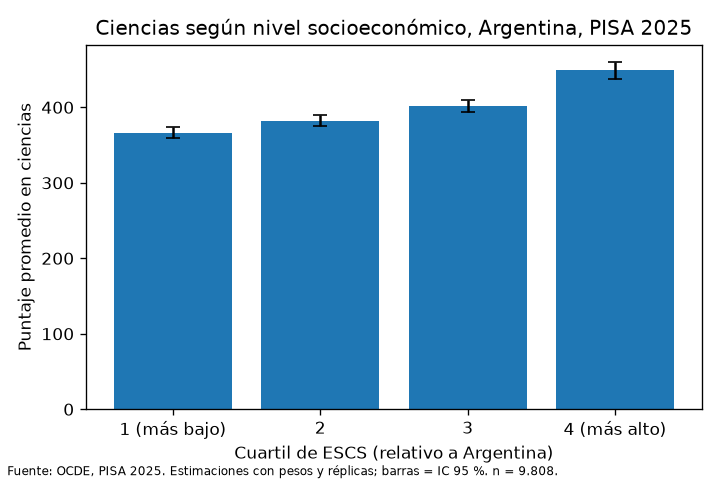

In [4]:
display(Image(filename=str(carpeta_figuras / "03_ciencias_por_cuartil_escs.png")))

### H2 · Uso de IA y nivel socioeconómico: se sostiene

Entre quienes contestaron, el uso frecuente de IA es más común en el cuartil de mayor ESCS que en el de menor ESCS en las cuatro actividades (diferencias de 13 a 17 puntos porcentuales). **Evidencia compatible con una asociación**: hay una brecha de uso que acompaña la brecha socioeconómica.

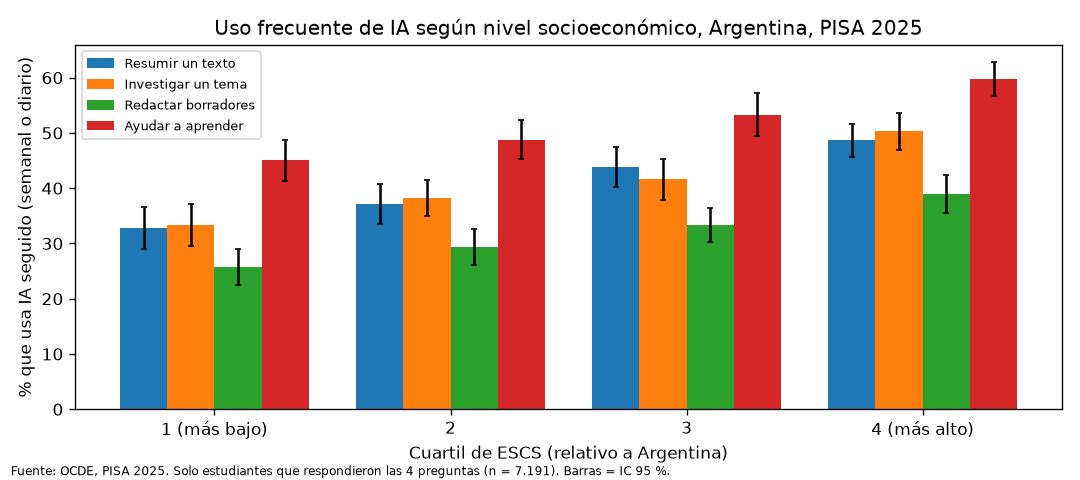

In [5]:
display(Image(filename=str(carpeta_figuras / "03_ia_seguido_por_cuartil_escs.png")))

### H3 · Rendimiento según el uso de IA, sin ajustar: se sostiene en tres de cuatro actividades

Quienes usan IA seguido (una vez por semana o más) tienen más puntaje de ciencias que quienes nunca la usan en investigar un tema (+28,4 puntos), ayudar a aprender (+26,6) y resumir un texto (+18,8). En redactar borradores el resultado no es concluyente (+7,1; el intervalo incluye el cero). Usar IA solo *a veces* no se distingue de no usarla. **Evidencia compatible con una asociación** para uso frecuente en tres actividades; **evidencia insuficiente** en el resto.

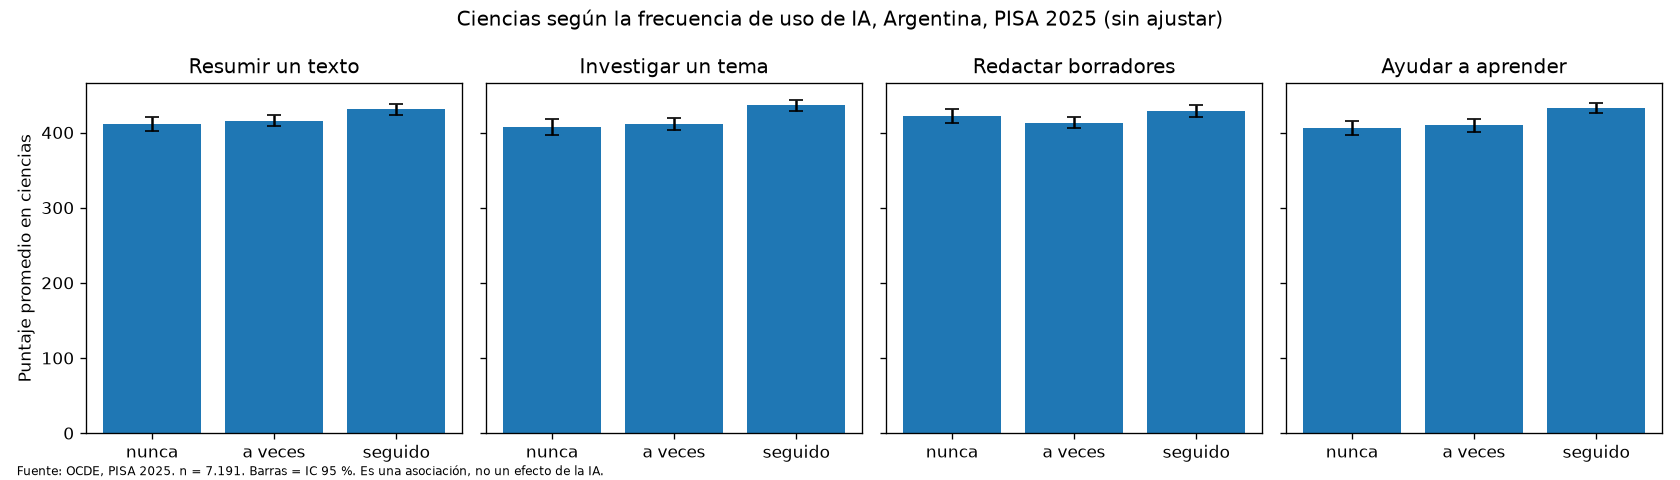

In [6]:
display(Image(filename=str(carpeta_figuras / "03_ciencias_por_frecuencia_ia.png")))

### H4 · Uso de IA y rendimiento ajustando por el contexto: se sostiene, pero es modesta

Ajustando por ESCS, sexo y grado, la asociación baja de +9,5 a **+4,0 puntos por punto de frecuencia** (IC 95 %: 1,1 a 6,9). Es decir, más de la mitad de la diferencia inicial va junto con el nivel socioeconómico. Por actividad persiste en investigar un tema y ayudar a aprender (alrededor de +5), y no es concluyente en resumir y redactar borradores. **Evidencia compatible con una asociación condicional, de tamaño modesto.**

### H5 (exploratoria) · ¿Cambia la asociación según el nivel socioeconómico?: no concluyente

La interacción es de +2,4 puntos (IC 95 %: -0,3 a 5,2): sugiere que la asociación podría ser algo mayor en los de mayor ESCS, pero el intervalo incluye el cero. **Evidencia insuficiente.**

### HC1 (complementaria) · Los que no contestaron las preguntas de IA

Surgió al preparar los datos y no estaba en el plan original. Los estudiantes que no contestaron las cuatro preguntas de IA (excluyendo a 526 a quienes la pregunta no se administró) tienen **66,0 puntos menos de ciencias** que los que sí contestaron (IC 95 %: 57,7 a 74,2), y 53,8 puntos menos si se ajusta por ESCS. **Evidencia compatible con una asociación.** Es la razón por la que los resultados sobre IA no deben extenderse sin cuidado a todos los estudiantes.

## 4. ¿Cambian las conclusiones si se miden las cosas de otra manera?

Se probaron pocas variantes decididas de antemano (otras áreas, otras medidas de IA, otros controles y un contraste más estricto). Detalle en el notebook 04.

In [7]:
print(sensibilidad[["hipotesis", "parametro", "n", "estimacion", "ic95_inferior", "ic95_superior", "p_texto"]].to_string(index=False))

            hipotesis                                                            parametro    n  estimacion  ic95_inferior  ic95_superior p_texto
              A. Área                                                      Ciencias (base) 7191       4.027          1.138          6.916  0.0063
              A. Área                                                           Matemática 7191       4.191          1.914          6.468  0.0003
              A. Área                                                              Lectura 7191       3.314          0.804          5.823  0.0097
      B. Medida de IA                       Índice AIUSESCH (puntos por unidad del índice) 7431       3.607          0.359          6.855  0.0295
      B. Medida de IA                 Usa IA alguna vez en alguna actividad (sí contra no) 7191       6.105         -6.504         18.714  0.3427
      B. Medida de IA           Usa IA semanal o diaria en alguna actividad (sí contra no) 7191      14.290          7.632  

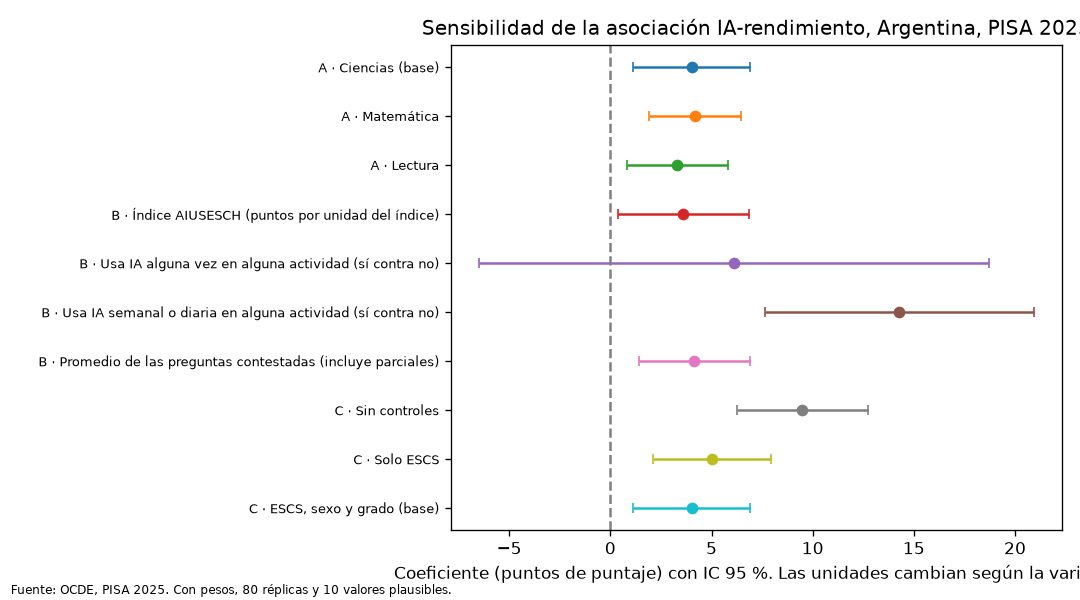

In [8]:
display(Image(filename=str(carpeta_figuras / "04_sensibilidad.png")))

**En resumen:** el signo positivo y el patrón por actividad se mantienen en todas las variantes. El tamaño de la asociación depende sobre todo de los controles que se usen. Con la definición "alguna vez" no hay resultado concluyente porque casi todos los estudiantes (92 %) usaron IA alguna vez.

## 5. Lo que NO se puede afirmar

- **Que la IA cause un mejor o peor rendimiento.** PISA es una encuesta de un solo momento. Las asociaciones también pueden deberse a que quienes rinden más usan más la IA, o a características de los estudiantes que no medimos.
- **Que los resultados valgan para todos los estudiantes.** Alrededor de un tercio no contestó las preguntas de IA y rinde bastante menos.
- **Nada sobre "copia directa" o perfiles de uso.** PISA no pregunta eso: solo la frecuencia de cuatro actividades.
- **Nada sobre los jóvenes que no están en la escuela.** PISA representa a estudiantes escolarizados de 15 años.
- **El uso de IA es autorreportado**, y el nivel socioeconómico es un índice relativo de Argentina, no el ingreso de las familias.
- **Hay supuestos técnicos sin confirmar:** el factor de Fay (0,5) de la fórmula de varianza no se verificó en la documentación técnica de PISA 2025 (que es provisional hasta 2027), y los resultados no se contrastaron con software estadístico de terceros, aunque un cálculo independiente los reprodujo.
- **Comparaciones múltiples:** solo H3 se informó con corrección de Bonferroni; los resultados límite (por ejemplo p cercano a 0,05) deben leerse con cautela.

## 6. Conclusión

En Argentina, en PISA 2025, el nivel socioeconómico se asocia fuertemente con el rendimiento y también con la frecuencia de uso de IA: los estudiantes de mayor nivel socioeconómico usan más seguido estas herramientas. Entre quienes contestaron, el uso frecuente en tareas de investigar, ayudar a aprender y resumir se asocia con mayor puntaje, pero esa asociación es modesta una vez que se tiene en cuenta el contexto y no permite decir que la IA mejore el aprendizaje.

Para la comunidad educativa, lo más sólido que dejan los datos es la **brecha de uso**: no todos los estudiantes usan estas herramientas con la misma frecuencia, y esa diferencia acompaña la desigualdad socioeconómica que ya existe en el rendimiento. Para saber si usar IA ayuda a aprender haría falta un diseño que permita estudiar causas (por ejemplo, seguimiento en el tiempo o un estudio con intervención), que PISA no ofrece.

## 7. Qué revisar si se actualiza el trabajo

- Cuando se publique el informe técnico final de PISA 2025 (previsto para 2027): confirmar el factor de replicación y el tratamiento de los pesos.
- Si hay nuevos ciclos de PISA: revisar si cambiaron las preguntas de IA y la cobertura en Argentina.
- Ante cualquier cambio de la estructura de los archivos, los notebooks tienen controles de calidad que se detienen con un error.